案例1: 阶跃函数的非局部全变分
ε = 0.500: TV_ε = 0.9970 (TV_ε^0 = 0.4985, TV_ε^1 = 0.4985)
ε = 0.200: TV_ε = 0.9910 (TV_ε^0 = 0.4955, TV_ε^1 = 0.4955)
ε = 0.100: TV_ε = 0.9810 (TV_ε^0 = 0.4905, TV_ε^1 = 0.4905)
ε = 0.050: TV_ε = 0.9610 (TV_ε^0 = 0.4805, TV_ε^1 = 0.4805)
ε = 0.020: TV_ε = 0.9009 (TV_ε^0 = 0.4505, TV_ε^1 = 0.4505)

理论极限 (ε→0): TV = 1.0


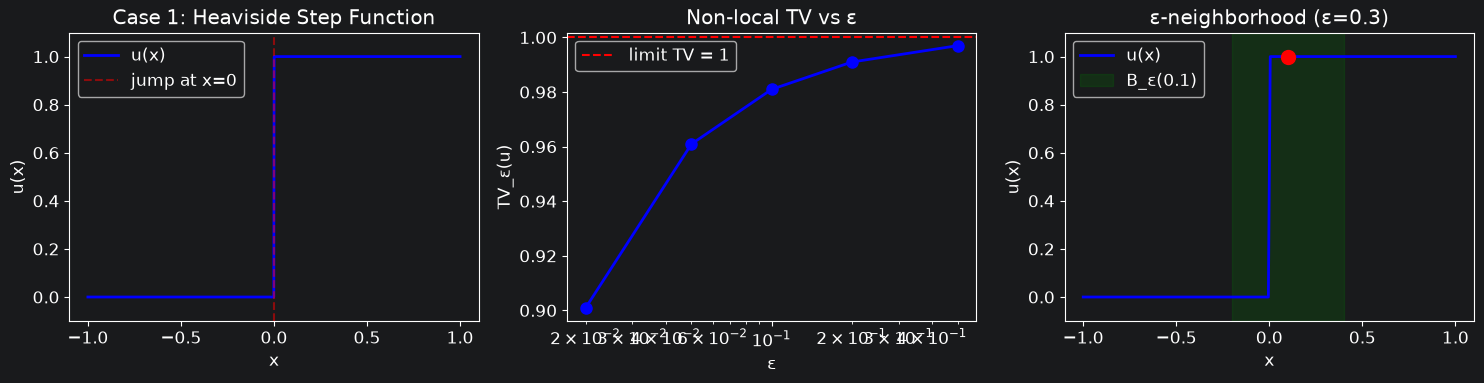


✓ 案例1完成: 当ε→0时，TV_ε→1（局部全变分）


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

# 设置中文字体（如果需要）
plt.rcParams['font.size'] = 12

# ============================================
# 案例1: 非局部全变分 TV_epsilon 的基本计算
# ============================================

def compute_nonlocal_tv_1d(u, x_grid, rho_0, rho_1, epsilon):
    """
    计算一维非局部全变分
    
    参数:
        u: 函数值数组 (在x_grid上的值)
        x_grid: 均匀网格点
        rho_0, rho_1: 两个类别的密度函数（在x_grid上的值）
        epsilon: 对抗预算
    """
    n = len(x_grid)
    dx = x_grid[1] - x_grid[0]
    
    tv_0 = 0.0  # 外周长部分
    tv_1 = 0.0  # 内周长部分
    
    for i in range(n):
        x = x_grid[i]
        # 找到 B_epsilon(x) 内的所有点
        neighbors = np.where(np.abs(x_grid - x) <= epsilon)[0]
        
        # 本质上确界和本质下确界（在离散情况下就是max/min）
        ess_sup = np.max(u[neighbors])
        ess_inf = np.min(u[neighbors])
        
        tv_0 += (ess_sup - u[i]) * rho_0[i] * dx
        tv_1 += (u[i] - ess_inf) * rho_1[i] * dx
    
    tv = (tv_0 + tv_1) / epsilon
    return tv, tv_0/epsilon, tv_1/epsilon

# 测试：阶跃函数
x = np.linspace(-1, 1, 1000)
u_step = np.where(x > 0, 1.0, 0.0)  # Heaviside阶跃函数

# 均匀密度
rho_0 = np.ones_like(x) * 0.5  # 类别0的密度
rho_1 = np.ones_like(x) * 0.5  # 类别1的密度

epsilon_values = [0.5, 0.2, 0.1, 0.05, 0.02]

print("=" * 60)
print("案例1: 阶跃函数的非局部全变分")
print("=" * 60)

results = []
for eps in epsilon_values:
    tv, tv0, tv1 = compute_nonlocal_tv_1d(u_step, x, rho_0, rho_1, eps)
    results.append((eps, tv, tv0, tv1))
    print(f"ε = {eps:.3f}: TV_ε = {tv:.4f} (TV_ε^0 = {tv0:.4f}, TV_ε^1 = {tv1:.4f})")

# 理论极限：局部全变分 = 跳跃高度 × 1 = 1
print(f"\n理论极限 (ε→0): TV = 1.0")

# 可视化
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 绘制阶跃函数
ax = axes[0]
ax.plot(x, u_step, 'b-', linewidth=2, label='u(x)')
ax.axvline(x=0, color='r', linestyle='--', alpha=0.5, label='jump at x=0')
ax.set_xlabel('x')
ax.set_ylabel('u(x)')
ax.set_title('Case 1: Heaviside Step Function')
ax.legend()
ax.set_ylim(-0.1, 1.1)

# 绘制 TV_epsilon 随 epsilon 变化
ax = axes[1]
epsilons = [r[0] for r in results]
tvs = [r[1] for r in results]
ax.plot(epsilons, tvs, 'bo-', linewidth=2, markersize=8)
ax.axhline(y=1.0, color='r', linestyle='--', label='limit TV = 1')
ax.set_xlabel('ε')
ax.set_ylabel('TV_ε(u)')
ax.set_title('Non-local TV vs ε')
ax.legend()
ax.set_xscale('log')

# 绘制密度和邻域示意
ax = axes[2]
x_demo = np.linspace(-1, 1, 200)
u_demo = np.where(x_demo > 0, 1.0, 0.0)
ax.plot(x_demo, u_demo, 'b-', linewidth=2, label='u(x)')
# 标记一个点的邻域
x_center = 0.1
eps_demo = 0.3
ax.axvspan(x_center - eps_demo, x_center + eps_demo, alpha=0.2, color='green', label=f'B_ε({x_center})')
ax.scatter([x_center], [u_demo[np.argmin(np.abs(x_demo - x_center))]], color='red', s=100, zorder=5)
ax.set_xlabel('x')
ax.set_ylabel('u(x)')
ax.set_title(f'ε-neighborhood (ε={eps_demo})')
ax.legend()
ax.set_ylim(-0.1, 1.1)

plt.tight_layout()
plt.savefig('../output/case1_nonlocal_tv.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✓ 案例1完成: 当ε→0时，TV_ε→1（局部全变分）")